<h1 style="text-align: center;">Simulación y Aplicaciones en Ciencias Sociales y Experimentales
</h3>
<h3 style="text-align: center;"> Práctica 2 </h3>

## Ejercicio 1 

En este ejercicio se propone modelar y simular el proceso de evolución de una epidemia. Los siguientes datos presentan el porcentaje de infectados de una población a lo largo de varias semanas. En el día 0 no había recuperados.  

In [1]:
days = [0, 14, 28, 42, 56, 70, 84, 98, 112, 126, 140, 156, 170, 184]
infected = [0.05, 0.17, 0.05,0.02, 0.01, 0.01, 0.01, 0.02, 0.03, 0.05, 0.04, 0.03, 0.02, 0.01]

**(a)** Tomar un modelo SIR clásico en tiempo continuo (debajo),

$$\begin{aligned}
\frac{ds}{dt} &= -\beta s x, \\
\frac{dx}{dt} &= \beta s x - \gamma x, \\
\frac{dr}{dt} &= \gamma x, \\
\end{aligned}$$ 

donde $s$, $x$ e $r$ son la tasa de susceptibles, infectados y recuperados, respectivamente. Inicialmente, se estima una duración media de la enfermedad de T=10 (por lo que la tasa de recuperación de la enfermedad es $\gamma= 1/T$) y una tasa de difusión de $\beta=0.4$. Re-estimar estos parámetros para que el modelo se ajuste lo mejor posible a los datos. Indicar el error cometido en el ajuste (MAE ó RMSE). 

**(b)** Extender el modelo anterior incluyendo la posibilidad de pérdida de inmunización. Se asume por tanto que los recuperados $r$, pasados una media de $T_p$ días, pasan a ser susceptibles de nuevo. Asumir los parámetros $\beta$, $\gamma$ óptimos calculados en el apartado (a) y $T_p=100$ días (esto es, una tasa de pérdida de inmunización de $\mu=1/T_p$). Estimar los parámetros $\beta$, $\gamma$ y $\mu$ para los que el modelo se ajusta lo mejor posible a los datos. Indicar si el modelo del apartado (a) o este modelo se ajusta mejor a los datos reales.

**(c)** Estudiar la sensibilidad de los parámetros del modelo del apartado (b) sobre el pico máximo de infectados en la segunda ola. Indicar qué parámetro tiene el mayor efecto sobre ese pico de infectados.

**(d)** Para el modelo del apartado (b), calcular por medio de las simulaciones (o analíticamente si se prefiere) el punto de equilibrio al que tienden las trayectorias. Indicar si el punto de equilibrio es estable o inestable. Observando la trayectoria de las variables, los valores propios de la matriz jacobiana en el punto de equilibrio, ¿tienen parte imaginaria distinta de cero?, ¿qué signo tiene la parte real de esos valores propios? 

### Apartado a) Modelo SIR

Las variables $s$, $x$ y $r$ representan las fracciones de susceptibles, infectados y recuperados:

$$\frac{ds}{dt}=-\beta sx,\qquad
\frac{dx}{dt}=\beta sx-\gamma x,\qquad
\frac{dr}{dt}=\gamma x.$$

Inicialmente, $x_0=0.05$, $r_0=0$ y $s_0=0.95$. Los datos se interpretan como fracciones de población: $0.05$ equivale al $5\%$.

Partimos de $\beta=0.4$ y $\gamma=1/10=0.1$. Las tasas se miden en día$^{-1}$, que significa «por día»: una duración media de 10 días corresponde a una tasa de recuperación $1/(10\ \text{días})=0.1\ \text{día}^{-1}$. Como $s$, $x$ y $r$ no tienen unidades y el tiempo se mide en días, $\beta$ también tiene unidades de $1/\text{día}$.

Simulamos el modelo mediante el método de Euler, con un paso de $0.01$ días.

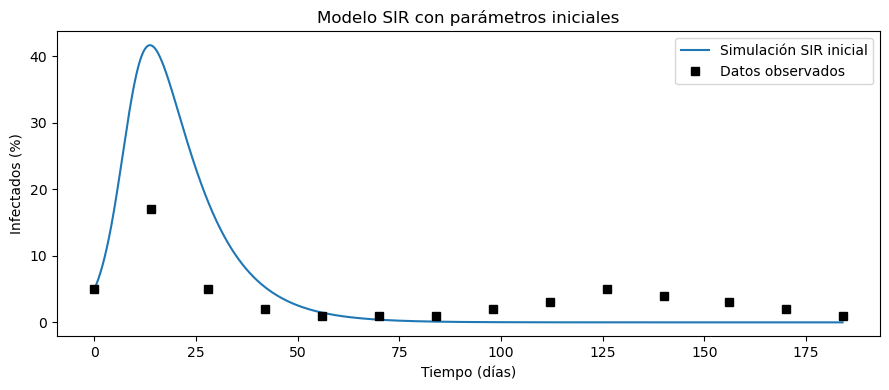

MAE inicial: 0.04488068
RMSE inicial: 0.07817632


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

df = pd.DataFrame({'infected': infected}, index=days)

# Definición del modelo
def sys(x, t, beta, gamma):
    dsdt = -beta*x[0]*x[1]
    dxdt = beta*x[0]*x[1] - gamma*x[1]
    drdt = gamma*x[1]
    return np.array([dsdt, dxdt, drdt])

# Definición del intervalo de tiempo
timestep = 0.01
t0 = 0
tf = days[-1]
t = np.linspace(t0, tf, int((tf-t0)/timestep + 1))
indices_datos = np.rint((df.index.to_numpy()-t0)/timestep).astype(int)

# Definición de los parámetros
beta = 0.4
T = 10
gamma = 1/T

# Valores iniciales de las variables de estado
s0 = 1-infected[0]
x0_infectados = infected[0]
r0 = 0
x0 = np.array([s0, x0_infectados, r0])

# Método de Euler
def solveODE_euler(f, x0, t, arg=()):
    n = len(t)
    x = np.zeros((n, len(x0)))
    x[0] = x0
    for i in range(n-1):
        x[i+1] = x[i] + (t[i+1]-t[i])*f(x[i], t[i], *arg)
    return x

sol_inicial = solveODE_euler(sys, x0, t, arg=(beta, gamma))

# Gráfica
plt.figure(figsize=(9, 4))
plt.plot(t, 100*sol_inicial[:, 1], label='Simulación SIR inicial')
plt.plot(df.index, 100*df.iloc[:, 0], 'ks', label='Datos observados')
plt.xlabel('Tiempo (días)')
plt.ylabel('Infectados (%)')
plt.title('Modelo SIR con parámetros iniciales')
plt.legend()
plt.tight_layout()
plt.show()

# Error del ajuste
mae_inicial = np.mean(np.abs(sol_inicial[indices_datos, 1]-df.iloc[:, 0].to_numpy()))
rmse_inicial = np.sqrt(np.mean((sol_inicial[indices_datos, 1]-df.iloc[:, 0].to_numpy())**2))
print(f'MAE inicial: {mae_inicial:.8f}')
print(f'RMSE inicial: {rmse_inicial:.8f}')

Reestimamos $\beta$ y $\gamma$ mediante mínimos cuadrados, manteniendo las condiciones iniciales. En cada simulación comparamos los infectados con las 14 observaciones en sus días correspondientes. Como el paso es $0.01$ días, convertimos esos días en posiciones de la matriz de resultados.

Minimizamos la suma de los residuos al cuadrado, $\sum_j[x(t_j)-x_j^{\mathrm{obs}}]^2$, y calculamos:

$$\mathrm{MAE}=\frac{1}{n}\sum_j|x(t_j)-x_j^{\mathrm{obs}}|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_j[x(t_j)-x_j^{\mathrm{obs}}]^2}.$$

Estos errores están en fracciones de población; multiplicarlos por 100 los expresa en puntos porcentuales.

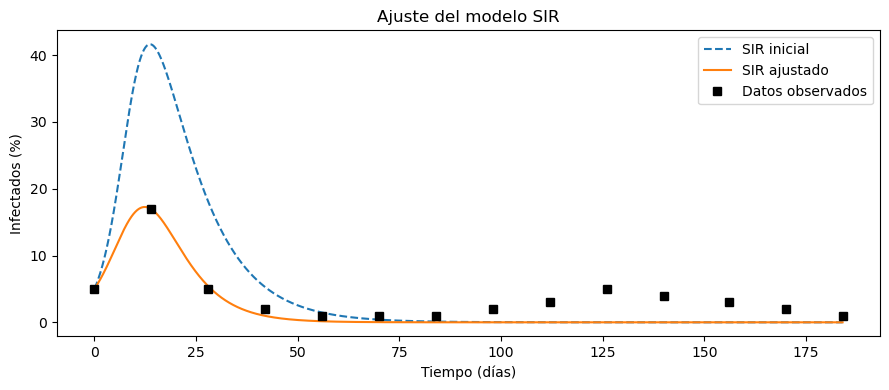

beta ajustada: 0.41636023 por día
gamma ajustada: 0.21241851 por día
Duración media de la infección: 4.7077 días
MAE: 0.01736385
RMSE: 0.02266020 (2.266020 puntos porcentuales)


In [3]:
# Ajuste por mínimos cuadrados
params = (beta, gamma)

def error_func(params, data):
    sol = solveODE_euler(sys, x0, t, arg=tuple(params))
    errors = sol[indices_datos, 1] - data.iloc[:, 0].to_numpy()
    return errors

best_params, cov, fit_details, mensaje, estado = optimize.leastsq(
    error_func, params, args=(df,), full_output=True
)
if estado not in (1, 2, 3, 4):
    raise RuntimeError(mensaje)

beta_opt, gamma_opt = best_params
sol_sir = solveODE_euler(sys, x0, t, arg=(beta_opt, gamma_opt))

# Gráfica
plt.figure(figsize=(9, 4))
plt.plot(t, 100*sol_inicial[:, 1], '--', label='SIR inicial')
plt.plot(t, 100*sol_sir[:, 1], label='SIR ajustado')
plt.plot(df.index, 100*df.iloc[:, 0], 'ks', label='Datos observados')
plt.xlabel('Tiempo (días)')
plt.ylabel('Infectados (%)')
plt.title('Ajuste del modelo SIR')
plt.legend()
plt.tight_layout()
plt.show()

# Error del ajuste
mae_sir = np.mean(np.abs(sol_sir[indices_datos, 1]-df.iloc[:, 0].to_numpy()))
rmse_sir = np.sqrt(np.mean((sol_sir[indices_datos, 1]-df.iloc[:, 0].to_numpy())**2))
print(f'beta ajustada: {beta_opt:.8f} por día')
print(f'gamma ajustada: {gamma_opt:.8f} por día')
print(f'Duración media de la infección: {1/gamma_opt:.4f} días')
print(f'MAE: {mae_sir:.8f}')
print(f'RMSE: {rmse_sir:.8f} ({100*rmse_sir:.6f} puntos porcentuales)')

Los parámetros estimados son $\beta\simeq 0.41636023$ y $\gamma\simeq 0.21241851$ por día. La duración media de la infección es $1/\gamma\simeq 4.7077$ días. El **RMSE es $0.02266020$**, equivalente a **2.266020 puntos porcentuales**.

El ajuste mejora la primera ola, pero no reproduce la segunda. En el SIR clásico, $s(t)$ solo disminuye; por tanto, una vez que $\beta s-\gamma$ se hace negativo, no puede volver a ser positivo y los infectados no pueden iniciar otra ola.

### Apartado b) Modelo SIRS

Los recuperados pierden la inmunidad y vuelven a ser susceptibles con tasa $\mu=1/T_p$. El modelo queda:

$$\frac{ds}{dt}=-\beta sx+\mu r,\qquad
\frac{dx}{dt}=\beta sx-\gamma x,\qquad
\frac{dr}{dt}=\gamma x-\mu r.$$

El término $\mu r$ pasa de recuperados a susceptibles, por lo que se conserva $s+x+r=1$. Partimos de los parámetros ajustados del SIR y $T_p=100$ días, es decir, $\mu=0.01$ por día. Esta es una duración media de la inmunidad.

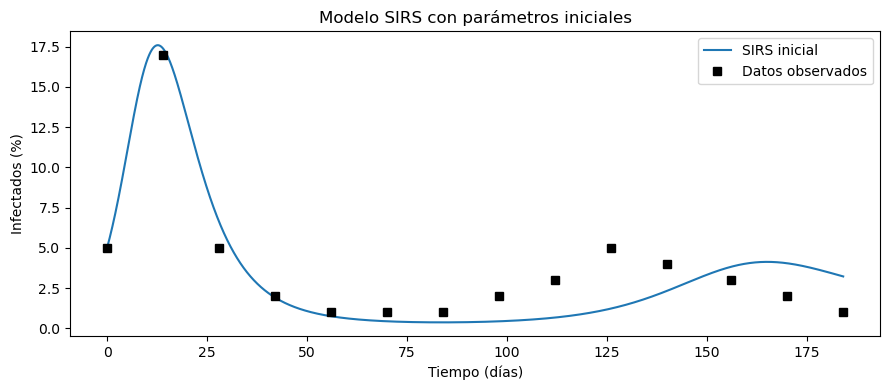

MAE inicial: 0.01283541
RMSE inicial: 0.01652842


In [4]:
# Definición del modelo
def sys2(x, t, beta, gamma, mu):
    dsdt = -beta*x[0]*x[1] + mu*x[2]
    dxdt = beta*x[0]*x[1] - gamma*x[1]
    drdt = gamma*x[1] - mu*x[2]
    return np.array([dsdt, dxdt, drdt])

# Definición del intervalo de tiempo
timestep = 0.01
t0 = 0
tf = days[-1]
t = np.linspace(t0, tf, int((tf-t0)/timestep + 1))

# Definición de los parámetros
beta = beta_opt
gamma = gamma_opt
Tp = 100
mu = 1/Tp

# Valores iniciales de las variables de estado
s0 = 1-infected[0]
x0_infectados = infected[0]
r0 = 0
x0 = np.array([s0, x0_infectados, r0])

# Aplicación del método de Euler
sol_sirs_inicial = solveODE_euler(sys2, x0, t, arg=(beta, gamma, mu))

# Gráfica
plt.figure(figsize=(9, 4))
plt.plot(t, 100*sol_sirs_inicial[:, 1], label='SIRS inicial')
plt.plot(df.index, 100*df.iloc[:, 0], 'ks', label='Datos observados')
plt.xlabel('Tiempo (días)')
plt.ylabel('Infectados (%)')
plt.title('Modelo SIRS con parámetros iniciales')
plt.legend()
plt.tight_layout()
plt.show()

# Error del ajuste
mae_sirs_inicial = np.mean(np.abs(sol_sirs_inicial[indices_datos, 1]-df.iloc[:, 0].to_numpy()))
rmse_sirs_inicial = np.sqrt(np.mean((sol_sirs_inicial[indices_datos, 1]-df.iloc[:, 0].to_numpy())**2))
print(f'MAE inicial: {mae_sirs_inicial:.8f}')
print(f'RMSE inicial: {rmse_sirs_inicial:.8f}')

Ajustamos conjuntamente las tres tasas $\beta$, $\gamma$ y $\mu$ mediante mínimos cuadrados. Se mantienen las condiciones iniciales y se utilizan las mismas observaciones que en el SIR.

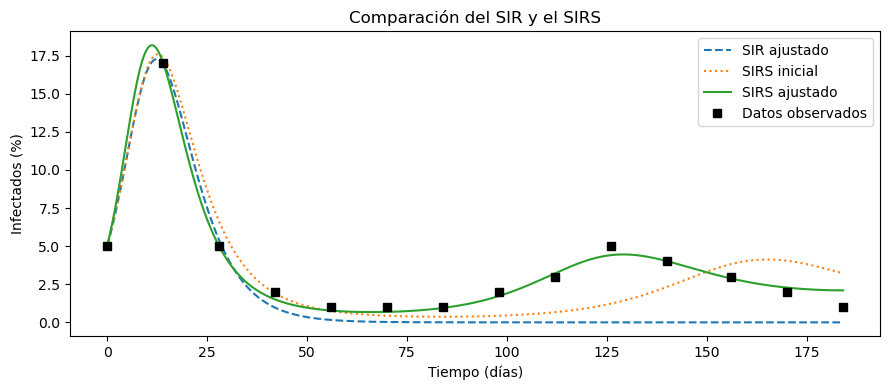

beta ajustada: 0.47480971 por día
gamma ajustada: 0.23836577 por día
mu ajustada: 0.01377943 por día
Duración media de la infección: 4.1952 días
Duración media de la inmunidad: 72.5719 días
MAE SIRS: 0.00265702
RMSE SIRS: 0.00393288 (0.393288 puntos porcentuales)
RMSE SIR: 0.02266020
Reducción del RMSE: 82.64 %


In [5]:
# Ajuste por mínimos cuadrados
params = (beta, gamma, mu)

def error_func_sirs(params, data):
    sol = solveODE_euler(sys2, x0, t, arg=tuple(params))
    errors = sol[indices_datos, 1] - data.iloc[:, 0].to_numpy()
    return errors

best_params, cov, fit_details, mensaje, estado = optimize.leastsq(
    error_func_sirs, params, args=(df,), full_output=True
)
if estado not in (1, 2, 3, 4):
    raise RuntimeError(mensaje)

beta_sirs, gamma_sirs, mu_sirs = best_params
sol_sirs = solveODE_euler(sys2, x0, t, arg=(beta_sirs, gamma_sirs, mu_sirs))

# Gráfica
plt.figure(figsize=(9, 4))
plt.plot(t, 100*sol_sir[:, 1], '--', label='SIR ajustado')
plt.plot(t, 100*sol_sirs_inicial[:, 1], ':', label='SIRS inicial')
plt.plot(t, 100*sol_sirs[:, 1], label='SIRS ajustado')
plt.plot(df.index, 100*df.iloc[:, 0], 'ks', label='Datos observados')
plt.xlabel('Tiempo (días)')
plt.ylabel('Infectados (%)')
plt.title('Comparación del SIR y el SIRS')
plt.legend()
plt.tight_layout()
plt.show()

# Error del ajuste
mae_sirs = np.mean(np.abs(sol_sirs[indices_datos, 1]-df.iloc[:, 0].to_numpy()))
rmse_sirs = np.sqrt(np.mean((sol_sirs[indices_datos, 1]-df.iloc[:, 0].to_numpy())**2))
mejora_rmse = 100*(1-rmse_sirs/rmse_sir)
print(f'beta ajustada: {beta_sirs:.8f} por día')
print(f'gamma ajustada: {gamma_sirs:.8f} por día')
print(f'mu ajustada: {mu_sirs:.8f} por día')
print(f'Duración media de la infección: {1/gamma_sirs:.4f} días')
print(f'Duración media de la inmunidad: {1/mu_sirs:.4f} días')
print(f'MAE SIRS: {mae_sirs:.8f}')
print(f'RMSE SIRS: {rmse_sirs:.8f} ({100*rmse_sirs:.6f} puntos porcentuales)')
print(f'RMSE SIR: {rmse_sir:.8f}')
print(f'Reducción del RMSE: {mejora_rmse:.2f} %')

Los parámetros estimados son $\beta\simeq 0.47480970$, $\gamma\simeq 0.23836577$ y $\mu\simeq 0.01377943$ por día. La duración media de la infección es **4.1952 días** y la de la inmunidad es **72.5719 días**.

El **RMSE baja a $0.00393288$**, equivalente a **0.393288 puntos porcentuales**: una reducción del **82.64 %** respecto al SIR. Por tanto, **el SIRS se ajusta mejor a estos datos**. La pérdida de inmunidad repone susceptibles y permite reproducir una segunda ola. La comparación corresponde al ajuste de las mismas observaciones y el SIRS tiene un parámetro adicional.

### Apartado c) Diseño de experimentos

Estudiamos el efecto de $\beta$, $\gamma$ y $\mu$ sobre el pico de infectados de la segunda ola mediante un **diseño factorial $2^3$**. Para cada tasa elegimos dos niveles: un $10\%$ por debajo y un $10\%$ por encima del valor ajustado. Así comparamos cambios porcentuales iguales.

La respuesta es la altura del **segundo máximo local** de infectados. No usamos el máximo de toda la trayectoria, que corresponde a la primera ola. Simulamos hasta 400 días, manteniendo las condiciones iniciales, para permitir que el segundo pico se desplace en el tiempo. Las tasas no se reajustan durante los experimentos.

| Combinación | $\beta$ | $\gamma$ | $\mu$ | Respuesta |
| --- | --- | --- | --- | --- |
| 1 | − | − | − | $R_1$ |
| 2 | + | − | − | $R_2$ |
| 3 | − | + | − | $R_3$ |
| 4 | + | + | − | $R_4$ |
| 5 | − | − | + | $R_5$ |
| 6 | + | − | + | $R_6$ |
| 7 | − | + | + | $R_7$ |
| 8 | + | + | + | $R_8$ |

In [6]:
from scipy.signal import find_peaks

# Definición del intervalo de tiempo
timestep = 0.01
t0 = 0
tf = 400
t_experimentos = np.linspace(t0, tf, int((tf-t0)/timestep + 1))

# Definición de los dos niveles de cada parámetro
beta = [0.9*beta_sirs, 1.1*beta_sirs]
gamma = [0.9*gamma_sirs, 1.1*gamma_sirs]
mu = [0.9*mu_sirs, 1.1*mu_sirs]
print('Niveles de beta:', np.round(beta, 8))
print('Niveles de gamma:', np.round(gamma, 8))
print('Niveles de mu:', np.round(mu, 8))

# Valores iniciales de las variables de estado
x0 = np.array([1-infected[0], infected[0], 0.0])

# Altura y día del segundo pico de infectados
def segundo_pico(sol, tiempos):
    picos, _ = find_peaks(sol[:, 1])
    if len(picos) < 2:
        raise ValueError('No aparece una segunda ola en el intervalo simulado.')
    indice = picos[1]
    return sol[indice, 1], tiempos[indice]

# Ocho simulaciones: beta cambia más rápido y mu más despacio
R3 = []
dias_picos = []
combinaciones = []
for k in range(len(mu)):
    for i in range(len(gamma)):
        for j in range(len(beta)):
            sol = solveODE_euler(sys2, x0, t_experimentos,
                                 arg=(beta[j], gamma[i], mu[k]))
            altura, dia = segundo_pico(sol, t_experimentos)
            R3.append(altura)
            dias_picos.append(dia)
            combinaciones.append([beta[j], gamma[i], mu[k]])

tabla_experimentos = pd.DataFrame(combinaciones, columns=['beta', 'gamma', 'mu'])
tabla_experimentos.index = np.arange(1, 9)
tabla_experimentos['Segundo pico (%)'] = 100*np.array(R3)
tabla_experimentos['Día del pico'] = dias_picos
print(tabla_experimentos.to_string(float_format=lambda x: f'{x:.6f}'))

Niveles de beta: [0.42732874 0.52229068]
Niveles de gamma: [0.21452919 0.26220235]
Niveles de mu: [0.01240149 0.01515738]
      beta    gamma       mu  Segundo pico (%)  Día del pico
1 0.427329 0.214529 0.012401          4.457845    143.390000
2 0.522291 0.214529 0.012401          5.355098    119.870000
3 0.427329 0.262202 0.012401          3.077124    161.990000
4 0.522291 0.262202 0.012401          4.215528    131.270000
5 0.427329 0.214529 0.015157          4.792442    129.280000
6 0.522291 0.214529 0.015157          5.749692    108.050000
7 0.427329 0.262202 0.015157          3.275828    145.000000
8 0.522291 0.262202 0.015157          4.458769    117.320000


Calculamos el efecto medio de cada parámetro como el cambio medio de la respuesta al pasar del nivel bajo al alto:

$$e_\beta=\frac{(R_2-R_1)+(R_4-R_3)+(R_6-R_5)+(R_8-R_7)}{4},$$
$$e_\gamma=\frac{(R_3-R_1)+(R_4-R_2)+(R_7-R_5)+(R_8-R_6)}{4},$$
$$e_\mu=\frac{(R_5-R_1)+(R_6-R_2)+(R_7-R_3)+(R_8-R_4)}{4}.$$

También calculamos las interacciones de dos factores, que miden cómo cambia el efecto de una tasa al modificar otra. Por ejemplo:

$$e_{\beta\gamma}=\frac{1}{2}\left[\frac{(R_4-R_3)+(R_8-R_7)}{2}-\frac{(R_2-R_1)+(R_6-R_5)}{2}\right].$$

Un efecto positivo aumenta el pico y uno negativo lo reduce. Para determinar qué tasa tiene mayor efecto, comparamos los valores absolutos de sus efectos principales. Los multiplicamos por 100 para expresarlos en puntos porcentuales de población.

Efectos en puntos porcentuales:
Efecto beta: +1.043962
Efecto gamma: -1.331957
Efecto mu: +0.292784
Interacción beta-gamma: +0.116710
Interacción beta-mu: +0.026133
Interacción gamma-mu: -0.071812


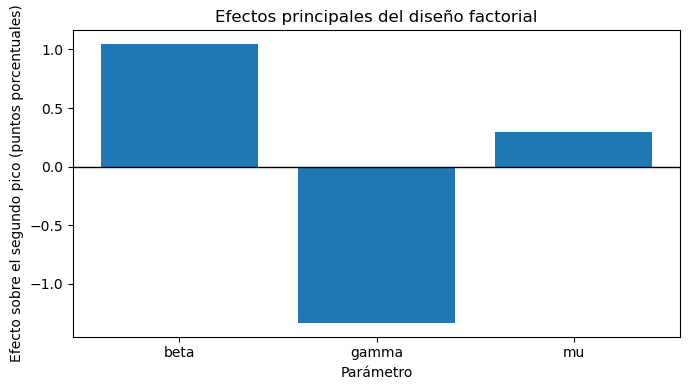

In [7]:
# Efectos principales
e1 = ((R3[1]-R3[0])+(R3[3]-R3[2])+(R3[5]-R3[4])+(R3[7]-R3[6]))/4
e2 = ((R3[2]-R3[0])+(R3[3]-R3[1])+(R3[6]-R3[4])+(R3[7]-R3[5]))/4
e3 = ((R3[4]-R3[0])+(R3[5]-R3[1])+(R3[6]-R3[2])+(R3[7]-R3[3]))/4

# Efectos de interacción
e12 = (((R3[3]-R3[2])+(R3[7]-R3[6]))/2-((R3[1]-R3[0])+(R3[5]-R3[4]))/2)/2
e13 = (((R3[5]-R3[4])+(R3[7]-R3[6]))/2-((R3[1]-R3[0])+(R3[3]-R3[2]))/2)/2
e23 = (((R3[6]-R3[4])+(R3[7]-R3[5]))/2-((R3[2]-R3[0])+(R3[3]-R3[1]))/2)/2

print('Efectos en puntos porcentuales:')
print(f'Efecto beta: {100*e1:+.6f}')
print(f'Efecto gamma: {100*e2:+.6f}')
print(f'Efecto mu: {100*e3:+.6f}')
print(f'Interacción beta-gamma: {100*e12:+.6f}')
print(f'Interacción beta-mu: {100*e13:+.6f}')
print(f'Interacción gamma-mu: {100*e23:+.6f}')

# Gráfica de los efectos principales
plt.figure(figsize=(7, 4))
plt.bar(['beta', 'gamma', 'mu'], 100*np.array([e1, e2, e3]))
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Parámetro')
plt.ylabel('Efecto sobre el segundo pico (puntos porcentuales)')
plt.title('Efectos principales del diseño factorial')
plt.tight_layout()
plt.show()

Los efectos principales de $\beta$, $\gamma$ y $\mu$ son, respectivamente, **+1.043962**, **-1.331957** y **+0.292784 puntos porcentuales**.

**El parámetro $\gamma$ tiene el mayor efecto sobre la altura del segundo pico**, porque su efecto principal presenta el mayor valor absoluto. Aumentar $\gamma$ reduce el pico; aumentar $\beta$ o $\mu$ lo eleva en las combinaciones estudiadas. Las interacciones tienen menor magnitud que los efectos principales.

Esta conclusión se refiere a los niveles elegidos, que representan cambios porcentuales iguales alrededor de los parámetros ajustados.

### Apartado d) Equilibrio y estabilidad

Simulamos el SIRS con los parámetros ajustados hasta 2000 días para observar el comportamiento a largo plazo. Mantenemos las mismas condiciones iniciales y el paso de Euler de $0.01$ días. El último estado de la simulación proporciona una aproximación al equilibrio al que tiende la trayectoria.

Estado al final de la simulación (s, x, r): [0.50202379 0.0272138  0.47076241]
Estado final en porcentajes: [50.202379  2.72138  47.076241]


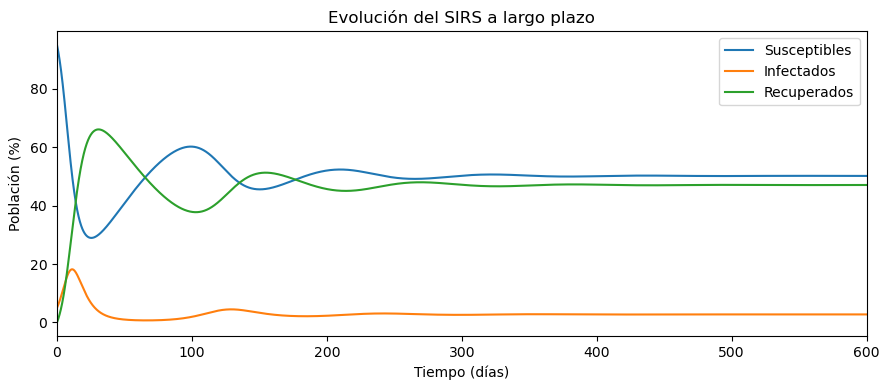

In [8]:
# Definición del intervalo de tiempo
timestep = 0.01
t0 = 0
tf = 2000
t_largo = np.linspace(t0, tf, int((tf-t0)/timestep + 1))

# Definición de los parámetros
beta = beta_sirs
gamma = gamma_sirs
mu = mu_sirs

# Valores iniciales de las variables de estado
s0 = 1-infected[0]
x0_infectados = infected[0]
r0 = 0
x0 = np.array([s0, x0_infectados, r0])

# Aplicación del método de Euler
sol_largo = solveODE_euler(sys2, x0, t_largo, arg=(beta, gamma, mu))
pto_eq_sim = sol_largo[-1]
print('Estado al final de la simulación (s, x, r):', np.round(pto_eq_sim, 10))
print('Estado final en porcentajes:', np.round(100*pto_eq_sim, 6))

# Gráfica: primeros 600 días para apreciar las oscilaciones
plt.figure(figsize=(9, 4))
plt.plot(t_largo, 100*sol_largo[:, 0], label='Susceptibles')
plt.plot(t_largo, 100*sol_largo[:, 1], label='Infectados')
plt.plot(t_largo, 100*sol_largo[:, 2], label='Recuperados')
plt.xlim(0, 600)
plt.xlabel('Tiempo (días)')
plt.ylabel('Población (%)')
plt.title('Evolución del SIRS a largo plazo')
plt.legend()
plt.tight_layout()
plt.show()

Calculamos también el equilibrio analíticamente. Un **punto de equilibrio** es un estado en el que las proporciones de susceptibles, infectados y recuperados permanecen constantes. Lo representamos mediante $(s^*,x^*,r^*)$, donde el asterisco indica el valor de equilibrio. Para encontrarlo, igualamos las derivadas a cero:

$$\begin{aligned}
0&=-\beta s^*x^*+\mu r^*,\\
0&=\beta s^*x^*-\gamma x^*,\\
0&=\gamma x^*-\mu r^*,
\end{aligned}
\qquad s^*+x^*+r^*=1.$$

Empezamos por la ecuación de infectados y sacamos factor común:

$$0=\beta s^*x^*-\gamma x^*=x^*(\beta s^*-\gamma).$$

El producto es cero si $x^*=0$ o si $\beta s^*-\gamma=0$. Si $x^*=0$, la ecuación de recuperados implica $r^*=0$, porque $\mu>0$. Por conservación de la población, $s^*=1$. Así obtenemos el equilibrio sin infección $(1,0,0)$.

Para encontrar el equilibrio con infección presente, suponemos $x^*>0$. Podemos entonces dividir entre $x^*$ y despejar:

$$\beta s^*-\gamma=0\quad\Longrightarrow\quad
\boxed{s^*=\frac{\gamma}{\beta}}.$$

En este estado, los nuevos contagios igualan a las recuperaciones: $\beta s^*x^*=\gamma x^*$, por lo que la fracción de infectados no cambia. Esta expresión corresponde a `s_eq = gamma/beta`.

De la ecuación de recuperados obtenemos otra relación:

$$\gamma x^*=\mu r^*\quad\Longrightarrow\quad r^*=\frac{\gamma}{\mu}x^*.$$

Las recuperaciones compensan la pérdida de inmunidad. Sustituimos esta relación y el valor de $s^*$ en la conservación de la población:

$$\frac{\gamma}{\beta}+x^*+\frac{\gamma}{\mu}x^*=1.$$

Agrupamos los términos que contienen $x^*$ y despejamos:

$$x^*\left(1+\frac{\gamma}{\mu}\right)=1-\frac{\gamma}{\beta},$$

$$\boxed{x^*=\frac{1-\gamma/\beta}{1+\gamma/\mu}
=\frac{\mu(1-\gamma/\beta)}{\gamma+\mu}}.$$

Como ya hemos calculado $s^*=\gamma/\beta$, en el código escribimos `x_eq = mu*(1-s_eq)/(gamma+mu)`.

Finalmente, sustituimos $x^*$ en la expresión de los recuperados:

$$r^*=\frac{\gamma}{\mu}x^*
=\frac{\gamma}{\mu}\frac{\mu(1-\gamma/\beta)}{\gamma+\mu}
\quad\Longrightarrow\quad
\boxed{r^*=\frac{\gamma(1-\gamma/\beta)}{\gamma+\mu}}.$$

Esto corresponde a `r_eq = gamma*(1-s_eq)/(gamma+mu)`.

La ecuación de susceptibles también se satisface: como $\beta s^*x^*=\gamma x^*=\mu r^*$, resulta $-\beta s^*x^*+\mu r^*=0$. **En equilibrio siguen existiendo contagios, recuperaciones y pérdidas de inmunidad, pero los tres flujos se compensan.**

Este equilibrio se denomina **endémico**, porque mantiene una fracción positiva de infectados. Con tasas positivas, existe con $x^*>0$ cuando $\beta>\gamma$, como ocurre con las tasas ajustadas. Las siguientes líneas calculan sus coordenadas y las comparan con el estado final de la simulación. Su estabilidad se estudia después mediante los valores propios del jacobiano.

In [9]:
# Cálculo del punto de equilibrio
s_eq = gamma/beta
x_eq = mu*(1-s_eq)/(gamma+mu)
r_eq = gamma*(1-s_eq)/(gamma+mu)
pto_eq = np.array([s_eq, x_eq, r_eq])

print('Equilibrio analítico (s*, x*, r*):', np.round(pto_eq, 10))
print('Equilibrio en porcentajes:', np.round(100*pto_eq, 6))
print('Distancia del estado final al equilibrio:', np.linalg.norm(pto_eq_sim-pto_eq))
print('Derivadas en el equilibrio:', sys2(pto_eq, 0, beta, gamma, mu))

Equilibrio analítico (s*, x*, r*): [0.50202379 0.0272138  0.47076241]
Equilibrio en porcentajes: [50.202379  2.72138  47.076241]
Distancia del estado final al equilibrio: 2.9492380433263754e-13
Derivadas en el equilibrio: [0. 0. 0.]


Para estudiar la estabilidad calculamos los valores propios de la **matriz jacobiana** en el equilibrio. Esta matriz reúne las derivadas parciales de las ecuaciones: indica cómo cambia el ritmo de variación de cada grupo al modificar ligeramente una de las variables, manteniendo las demás constantes.

Llamamos $f_1=-\beta sx+\mu r$, $f_2=\beta sx-\gamma x$ y $f_3=\gamma x-\mu r$ a las tres ecuaciones. Cada fila del jacobiano corresponde a una ecuación y cada columna a una variable, en el orden $s,x,r$:

$$J=\begin{pmatrix}
\dfrac{\partial f_1}{\partial s}&\dfrac{\partial f_1}{\partial x}&\dfrac{\partial f_1}{\partial r}\\
\dfrac{\partial f_2}{\partial s}&\dfrac{\partial f_2}{\partial x}&\dfrac{\partial f_2}{\partial r}\\
\dfrac{\partial f_3}{\partial s}&\dfrac{\partial f_3}{\partial x}&\dfrac{\partial f_3}{\partial r}
\end{pmatrix}.$$

Por ejemplo, al derivar $f_1=-\beta sx+\mu r$ respecto a $s$, tratamos $x$ y $r$ como constantes y obtenemos $-\beta x$. Al derivarla respecto a $x$ obtenemos $-\beta s$, y respecto a $r$ obtenemos $\mu$. Así se construye la primera fila. Para $f_2$, las derivadas son $\beta x$, $\beta s-\gamma$ y $0$; para $f_3$, son $0$, $\gamma$ y $-\mu$. Por tanto:

$$J(s,x,r)=\begin{pmatrix}
-\beta x&-\beta s&\mu\\
\beta x&\beta s-\gamma&0\\
0&\gamma&-\mu
\end{pmatrix}.$$

Evaluamos la matriz en $(s^*,x^*,r^*)$. Cerca del equilibrio, una pequeña desviación $\delta X$ sigue aproximadamente el sistema lineal $\delta\dot X\simeq J(s^*,x^*,r^*)\,\delta X$. Los valores propios de esta matriz describen si esas desviaciones crecen, se amortiguan o presentan oscilaciones. En el código, `optimize.approx_fprime` aproxima el jacobiano mediante pequeñas variaciones de las coordenadas y `np.linalg.eig` calcula sus valores y vectores propios.

Como se conserva $s+x+r$, el jacobiano de las tres variables tiene un valor propio cero. Para decidir la estabilidad dentro de la población normalizada, consideramos perturbaciones que cumplen $\delta s+\delta x+\delta r=0$. Solo hay dos variables independientes: al conocer $s$ y $x$, queda determinado $r=1-s-x$.

Sustituimos esa expresión en las ecuaciones:

$$\dot s=-\beta sx+\mu(1-s-x),\qquad
\dot x=\beta sx-\gamma x.$$

Derivando ahora respecto a las dos variables independientes obtenemos el jacobiano reducido:

$$J_{\mathrm{red}}(s,x)=\begin{pmatrix}
-\beta x-\mu&-\beta s-\mu\\
\beta x&\beta s-\gamma
\end{pmatrix}.$$

Los términos adicionales $-\mu$ de la primera fila proceden de derivar $\mu(1-s-x)$ respecto a $s$ y a $x$. Esta matriz, evaluada en $(s^*,x^*)$, se construye directamente en el código como `J_reducido`.

En un sistema de tiempo continuo, si sus dos valores propios tienen **parte real negativa**, las pequeñas perturbaciones se amortiguan y el equilibrio es **localmente asintóticamente estable**. Si además tienen **parte imaginaria distinta de cero**, esa aproximación presenta oscilaciones amortiguadas. El valor propio cero del sistema completo, por sí solo, no permite decidir la estabilidad; la conclusión se obtiene estudiando las dos variables independientes.

In [10]:
# Cálculo de la matriz jacobiana en el punto de equilibrio
eps = np.sqrt(np.finfo(float).eps)
J = optimize.approx_fprime(pto_eq, sys2, eps, 0, beta, gamma, mu)

# Cálculo de los valores y vectores propios
eigenvalues, eigenvectors = np.linalg.eig(J)
print('Jacobiano de las tres variables:')
print(J)
print('Valores propios del sistema completo:', eigenvalues)

# Jacobiano de las dos variables independientes: r = 1-s-x
J_reducido = np.array([
    [-beta*x_eq-mu, -beta*s_eq-mu],
    [beta*x_eq, beta*s_eq-gamma]
])
eigenvalues_red, eigenvectors_red = np.linalg.eig(J_reducido)
print('\nValores propios del sistema reducido:', eigenvalues_red)
for valor in eigenvalues_red:
    print(f'Parte real: {valor.real:+.8f}; parte imaginaria: {valor.imag:+.8f}')
print('Ambas partes reales son negativas:', np.all(eigenvalues_red.real < 0))
print('Ambas partes imaginarias son distintas de cero:',
      np.all(np.abs(eigenvalues_red.imag) > 1e-8))

Jacobiano de las tres variables:
[[-1.29213773e-02 -2.38365771e-01  1.37794325e-02]
 [ 1.29213773e-02  5.82076609e-11  0.00000000e+00]
 [ 0.00000000e+00  2.38365771e-01 -1.37794325e-02]]
Valores propios del sistema completo: [-1.33504049e-02+0.05549622j -1.33504049e-02-0.05549622j
  1.45920316e-18+0.j        ]

Valores propios del sistema reducido: [-0.0133504+0.05549622j -0.0133504-0.05549622j]
Parte real: -0.01335040; parte imaginaria: +0.05549622
Parte real: -0.01335040; parte imaginaria: -0.05549622
Ambas partes reales son negativas: True
Ambas partes imaginarias son distintas de cero: True


La trayectoria tiende al equilibrio

$$\boxed{(s^*,x^*,r^*)\simeq(0.50202380,\;0.02721380,\;0.47076240)},$$

es decir, **50.2024 % de susceptibles, 2.7214 % de infectados y 47.0762 % de recuperados**. La infección persiste en una proporción constante de la población.

Los dos valores propios del sistema reducido son aproximadamente

$$\boxed{\lambda_{1,2}\simeq -0.01335041\pm 0.05549622\,i}\quad\text{día}^{-1}.$$

Tienen **parte real negativa** y **parte imaginaria distinta de cero**. Por tanto, el equilibrio es **localmente asintóticamente estable para perturbaciones que conservan $s+x+r=1$**: las oscilaciones se amortiguan y la trayectoria se aproxima al equilibrio, como muestra la simulación. El valor propio cero del sistema completo se debe a la conservación de la población y no indica inestabilidad.

También existe el equilibrio sin infección $(1,0,0)$, pero es inestable frente a la introducción de infectados porque $\beta-\gamma>0$.

## Ejercicio 2 <font size=1.5>  <font>

Partimos del modelo económico de la telaraña. Recuérdense los supuestos iniciales:  

- $D(p_t)$ es el producto demandado en el año $t$, que depende del precio $p_t$ del producto en ese año. Se asume una demanda lineal, por tanto, $D(p_t) = a -bp_t$, donde $a$ y $b$ son parámetros.
- Los productores toman decisiones de producción a partir de unas expectativas de precios $p_t^e$. Por tanto, la función de oferta es $S=S(p_t^e)$.
- Se asume un mercado en competencia perfecta, por lo que el precio del producto en cada año se obtiene como resultado de igualarse las funciones de oferta y demanda, esto es $D(p_t)=S(p_t^e)$. Despejando $p_t$ de esta ecuación se llega a:

$ p_t= \frac{a}{b} - \frac{S(p_t^e)}{b}. $


In [11]:
# Librerías de operaciones
import pandas as pd
import numpy as np

# Librerías de gráficos
import matplotlib.pyplot as plt
import seaborn as sns


**(a)** Asumimos el caso clásico en el que los productores esperan que el precio del periodo anterior se va a mantener, esto es $p_t^e=p_{t-1}$. Se asume que $p_0=2$ y los valores iniciales de los parámetros $a=14$, $b=2$, $c=2$, con $d>0$ desconocido. Encontrar el valor de $d$ en el que el comportamiento de los precios a largo plazo pasa de ser convergente a divergente. Indicar la ecuación del punto de equilibrio.


**Modelo y organización del código.** La oferta es $S(p^e)=c+dp^e$.
En este apartado $p_{t+1}^e=p_t$: el precio esperado para el siguiente año es
el precio real del año actual. Igualando oferta y demanda:
$$p_{t+1}=\frac{a-c-dp_t}{b}.$$

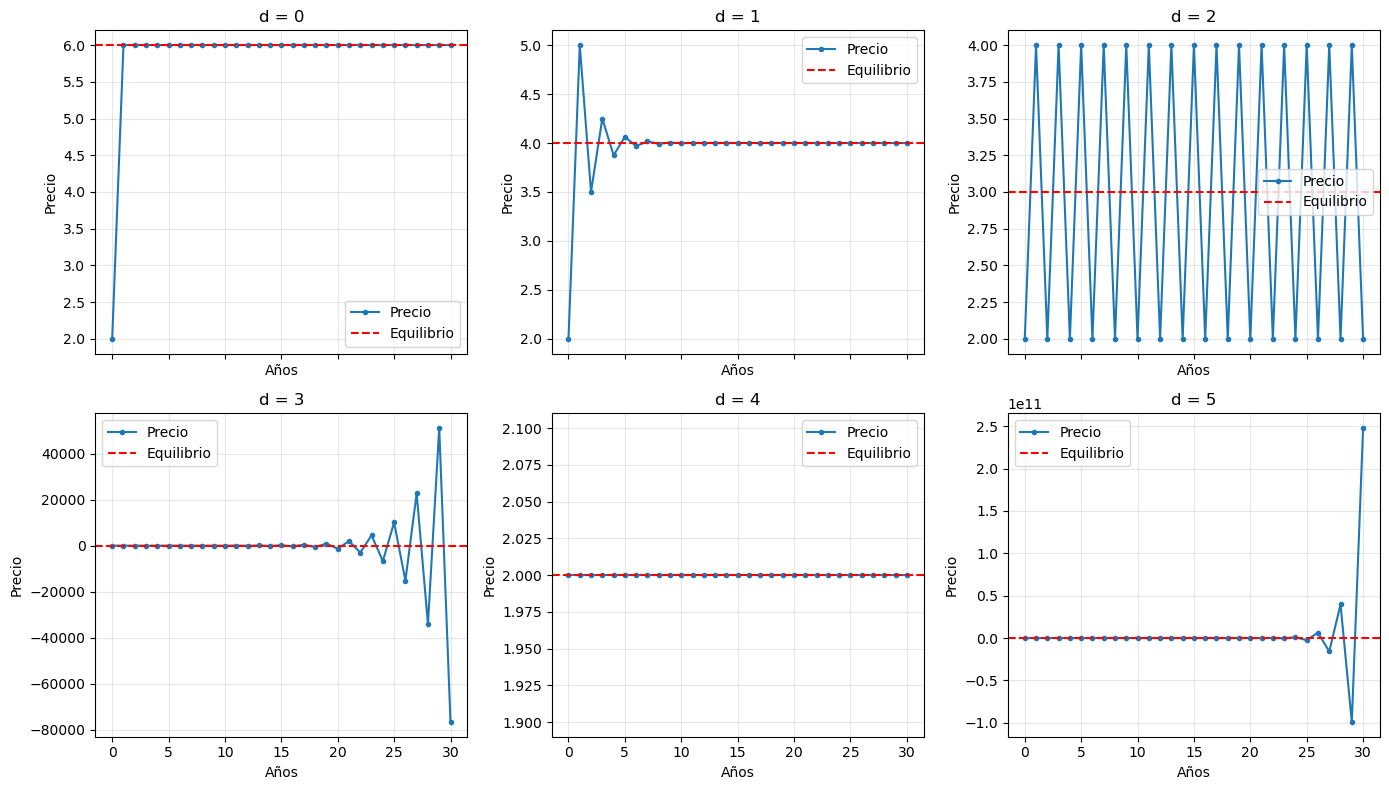

In [12]:
# Definición del modelo
def demand(p, a, b):
    return a - b*p

def supply(p, c, d):
    return c + d*p

def ge_a(p, t, a, b, c, d):
    pes = p[0]
    ps = (a - supply(pes, c, d))/b
    return np.array([ps])

def solve_disc_model(f, x0, t, arg=()):
    n = len(t)
    x = np.zeros((n, len(x0)))
    # x = np.zeros((n, len(x0)))
    x[0] = x0
    for i in range(n - 1):
        x[i+1] = f(x[i], t[i], *arg)
    return x

# Definición del tiempo, los parámetros y la condición inicial
a = 14
b = 2
c = 2
p0 = 2
p_a = [p0]
t_a = np.arange(0, 31)
d_array_a = np.linspace(0, 5, 6)

def sweep_d_a(d_array):
    solutions = {}
    for d in d_array:
        sol = solve_disc_model(ge_a, p_a, t_a, arg=(a, b, c, d))
        solutions[d] = sol
    return solutions

sol_d_a = sweep_d_a(d_array_a)

# Gráficas con una escala vertical para cada d
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)
for ax, (d_value, sol) in zip(axes.flat, sol_d_a.items()):
    p_equilibrio = (a-c)/(b+d_value)
    ax.plot(t_a, sol[:, 0], "o-", markersize=3, label="Precio")
    ax.axhline(p_equilibrio, color="red", linestyle="--", label="Equilibrio")
    ax.set_title(f"d = {d_value:g}")
    ax.set_xlabel("Años")
    ax.set_ylabel("Precio")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Equilibrio y umbral.** En equilibrio el precio se repite, por lo que
$a-bp^*=c+dp^*$ y
$$p^*=\frac{a-c}{b+d}=\frac{12}{2+d}.$$
Al restar el equilibrio de la ecuación del modelo:
$$p_{t+1}-p^*=-\frac d2(p_t-p^*).$$
La distancia al equilibrio se multiplica por $d/2$ en cada paso. Así, el umbral
es **$d=2$**: para $0<d<2$ hay convergencia; para $d=2$, oscilación de periodo
dos si no se empieza en equilibrio; para $d>2$, el equilibrio es inestable.

**Caso especial de la gráfica:** con $d=4$, $p^*=2=p_0$. La trayectoria es
constante porque ya empieza en el equilibrio, aunque este sea inestable.
El caso $d=0$ se incluye como referencia sin reacción de la oferta.

**Comprobación próxima al umbral.** El barrido entero anterior permite ver el
cambio general. Ahora observamos valores a ambos lados de 2 durante más años:
cerca del umbral el acercamiento o alejamiento puede ser lento.

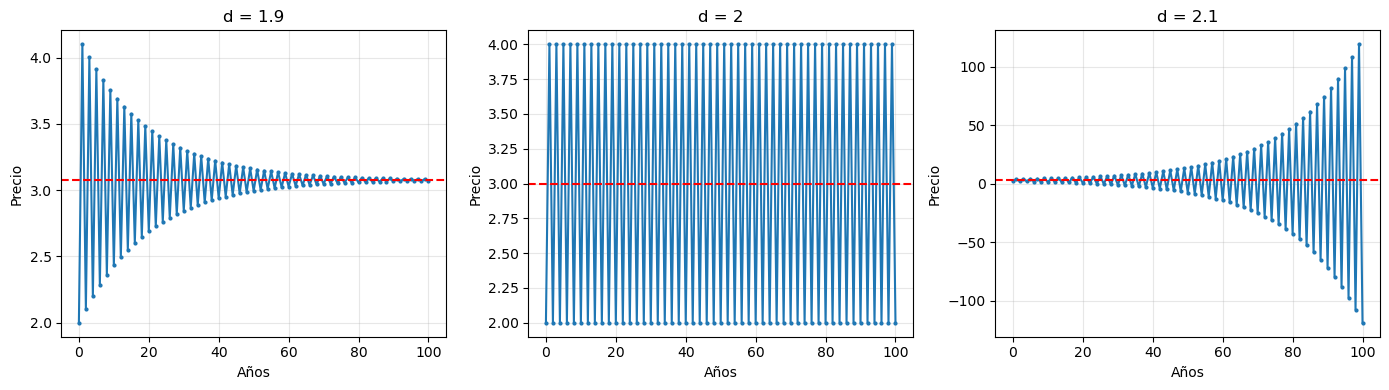

In [13]:
t_detalle_a = np.arange(0, 101)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, d in zip(axes, [1.9, 2.0, 2.1]):
    sol = solve_disc_model(ge_a, p_a, t_detalle_a, arg=(a, b, c, d))
    ax.plot(t_detalle_a, sol[:, 0], "o-", markersize=2)
    ax.axhline((a-c)/(b+d), color="red", linestyle="--")
    ax.set(title=f"d = {d:g}", xlabel="Años", ylabel="Precio")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**(b)** Ahora se asume el caso de *backward looking average expectation*, esto es, los productores fijan las expectativas de los precios de acuerdo a una media ponderada de los precios en los dos periodos anteriores: 

  $ p_t^e= (1-\alpha) p_{t-1} + \alpha p_{t-2}. $

Dados los precios iniciales $p_1=2$ y $p_0=1$, y los mismos valores de los parámetros que en el apartado anterior, $a=14$, $b=2$, $c=2$ y $d>0$, con $\alpha=0.5$, encontrar el valor de $d$ para que el comportamiento de los precios a largo plazo pase de ser convergente a divergente. Realizar un heatmap con los valores de $\alpha$ y $d$ diferenciando entre regiones convergentes, oscilantes y divergentes a largo plazo. (Nota: para utilizar el mismo proceso de simulación se puede definir una variable nueva $q_t=p_{t-1}$ y transformar el sistema en uno con tres variables


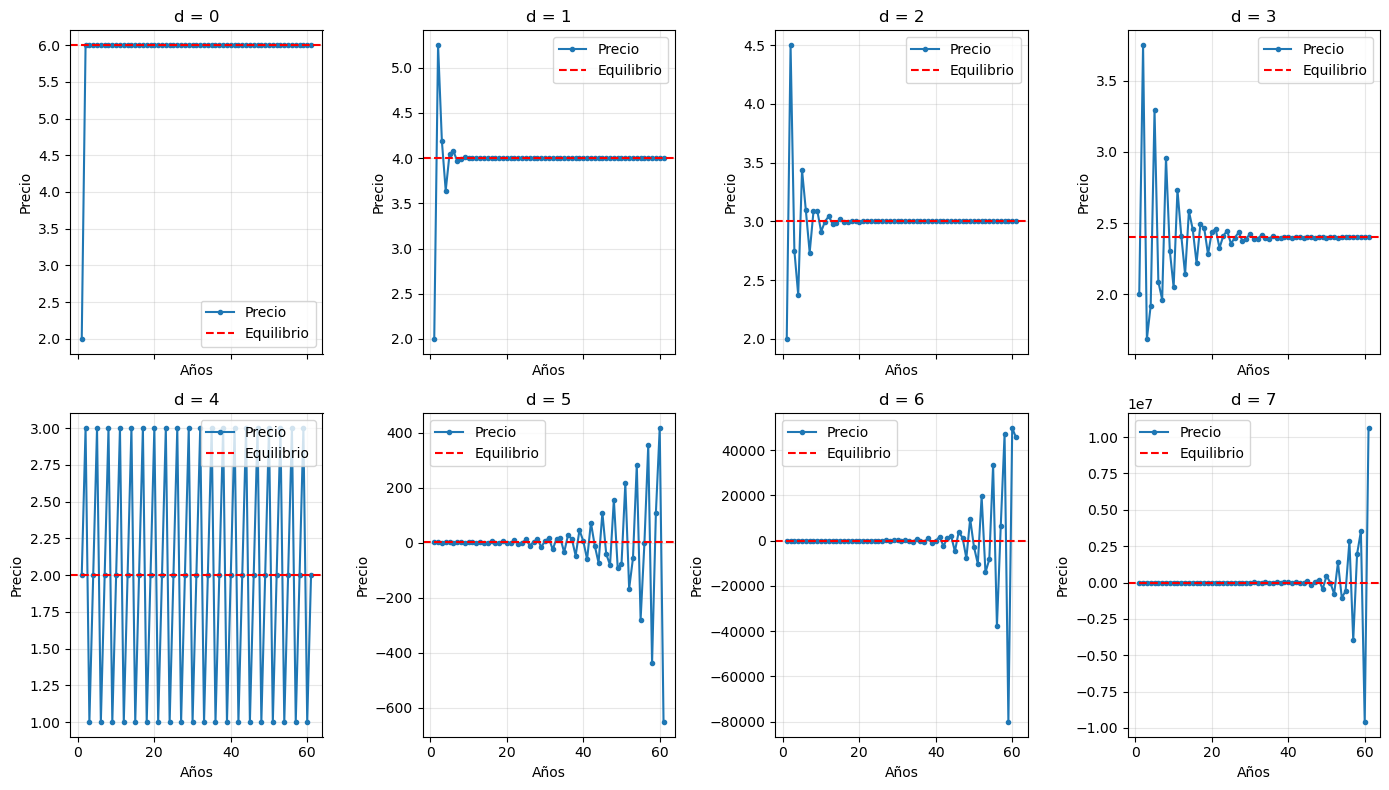

In [14]:
# Definición del modelo con dos precios anteriores
def ge_b(p, t, a, b, c, d, alpha):
    pes = (1-alpha)*p[0] + alpha*p[1]
    ps = (a - supply(pes, c, d))/b
    return np.array([ps, p[0]])

# Definición del tiempo, los parámetros y las condiciones iniciales
a = 14
b = 2
c = 2
alpha_b = 0.5
p1 = 2
p0 = 1
p_b = [p1, p0]
t_b = np.arange(1, 62)
d_array_b_trayectorias = np.linspace(0, 7, 8)

def sweep_d_b(d_array, alpha):
    solutions = {}
    for d in d_array:
        sol = solve_disc_model(ge_b, p_b, t_b, arg=(a, b, c, d, alpha))
        solutions[d] = sol
    return solutions

sol_d_b = sweep_d_b(d_array_b_trayectorias, alpha_b)

# Gráficas
fig, axes = plt.subplots(2, 4, figsize=(14, 8), sharex=True)
for ax, (d_value, sol) in zip(axes.flat, sol_d_b.items()):
    p_equilibrio = (a-c)/(b+d_value)
    ax.plot(t_b, sol[:, 0], "o-", markersize=3, label="Precio")
    ax.axhline(p_equilibrio, color="red", linestyle="--", label="Equilibrio")
    ax.set_title(f"d = {d_value:g}")
    ax.set_xlabel("Años")
    ax.set_ylabel("Precio")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Resultado para $\alpha=0.5$.** Las simulaciones sitúan la transición en torno
a **$d=4$**. En $d=4$, con estos precios iniciales, aparece el ciclo
$2,3,1,2,3,1,\ldots$. Por debajo del umbral las oscilaciones se amortiguan y por encima crecen. 

**Criterio común para los heatmaps.** Comparamos el máximo de
$|p_t-p^*|$ en dos ventanas finales consecutivas. Si baja, clasificamos como
convergente; si sube, divergente; si cambia poco, oscilante o cerca de la
frontera. Este criterio es **aproximado**: un cambio muy lento también puede
caer en la clase intermedia. Las oscilaciones amortiguadas son convergentes.
No basta con comprobar si dos precios tienen signos diferentes.

In [15]:
# Clasificación por amplitudes para los apartados b), c) y d)
# 0 -> Divergente; 0.5 -> Oscilante / frontera; 1 -> Convergente.
def clasificar_trayectoria(precios, p_equilibrio, ventana=40, margen=0.05):
    precios = np.asarray(precios)
    if len(precios) < 2*ventana:
        raise ValueError("Se necesitan al menos dos ventanas de observaciones.")
    if not np.all(np.isfinite(precios)):
        return 0.0

    error = np.abs(precios - p_equilibrio)
    amplitud_anterior = np.max(error[-2*ventana:-ventana])
    amplitud_final = np.max(error[-ventana:])
    tolerancia = 1e-4 * max(1, abs(p_equilibrio))

    if amplitud_final < tolerancia:
        return 1.0
    elif amplitud_final < (1-margen)*amplitud_anterior:
        return 1.0
    elif amplitud_final > (1+margen)*amplitud_anterior:
        return 0.0
    else:
        return 0.5

**Barridos de parámetros.** `sweep_alpha_b` cambia $\alpha$ dejando $d$ fijo;
`sweep_parameters_b` repite ese barrido para cada $d$. Las filas del DataFrame
corresponden a $d$ y las columnas a $\alpha$. Se emplean 1000 actualizaciones para observar el tramo final.

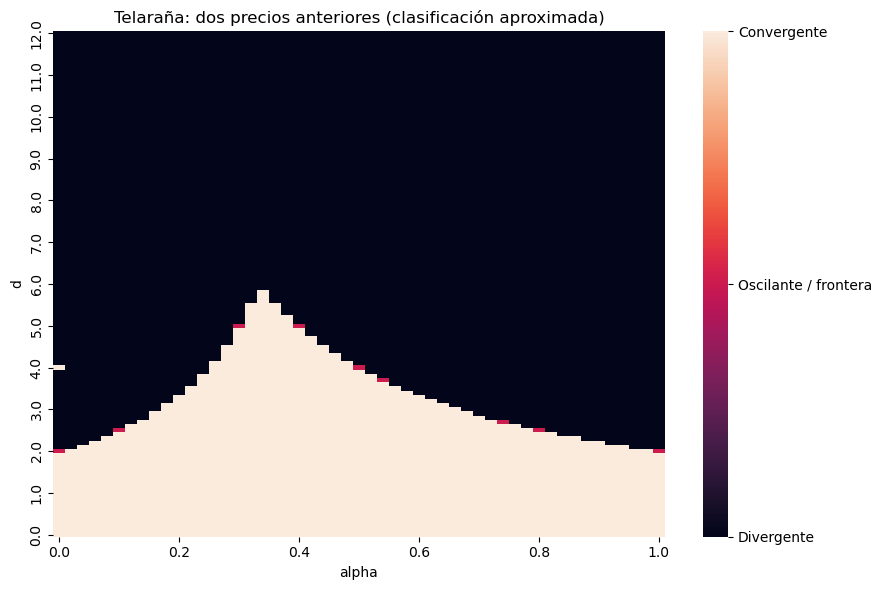

In [16]:
# Barrido de alpha y d
t_heat_b = np.arange(1, 1002)
d_array_heat = np.round(np.linspace(0, 12, 121), 2)
alpha_array_heat = np.round(np.linspace(0, 1, 51), 2)

def sweep_alpha_b(alpha_array, d):
    sweep = pd.Series(index=alpha_array, dtype=float)
    p_equilibrio = (a-c)/(b+d)
    for alpha in alpha_array:
        # Si una trayectoria desborda, se clasifica como divergente.
        with np.errstate(over="ignore", invalid="ignore"):
            sol = solve_disc_model(ge_b, p_b, t_heat_b, arg=(a, b, c, d, alpha))
        sweep.loc[alpha] = clasificar_trayectoria(sol[:, 0], p_equilibrio)
    return sweep

def sweep_parameters_b(alpha_array, d_array):
    frame = pd.DataFrame(index=d_array, columns=alpha_array, dtype=float)
    for d in d_array:
        frame.loc[d] = sweep_alpha_b(alpha_array, d)
    return frame

frame_b = sweep_parameters_b(alpha_array_heat, d_array_heat)

# Gráfica del mapa de calor
plt.figure(figsize=(9, 6))
hm = sns.heatmap(frame_b, annot=False, vmin=0, vmax=1,
                 xticklabels=10, yticklabels=10,
                 cbar_kws={"ticks": [0, 0.5, 1]})
hm.invert_yaxis()
barra = hm.collections[0].colorbar
barra.set_ticklabels(["Divergente", "Oscilante / frontera", "Convergente"])
plt.xlabel("alpha")
plt.ylabel("d")
plt.title("Telaraña: dos precios anteriores (clasificación aproximada)")
plt.tight_layout()
plt.show()

**Lectura del heatmap.** Cada casilla resume una simulación para una pareja
$(\alpha,d)$. Con $\alpha=0$ solo se usa el último precio y se recupera la
frontera del apartado (a), $d=2$. Con $\alpha=0.5$, la transición está cerca de
$d=4$. La clase intermedia señala oscilaciones persistentes o casos que el
horizonte y las tolerancias no distinguen con suficiente precisión.


**(c)** Tomar el modelo del apartado (b) alargando los periodos que se toman para estimar precios. O sea, la expectativa de precios en el tiempo $t$ es la media ponderada de los precios $p_{t-1}$, $p_{t-2}$ y $p_{t-3}$. El precio más alejado tiene un ponderación de $\alpha$ y los otros dos se reparten a partes iguales el resto de la ponderación $1-\alpha$. Dados los precios iniciales $p_2=2$ y $p_1=1$ y $p_0=1$, realizar un heatmap con los valores de $\alpha$ y $d$ diferenciando entre regiones convergentes, oscilantes y divergentes a largo plazo. 


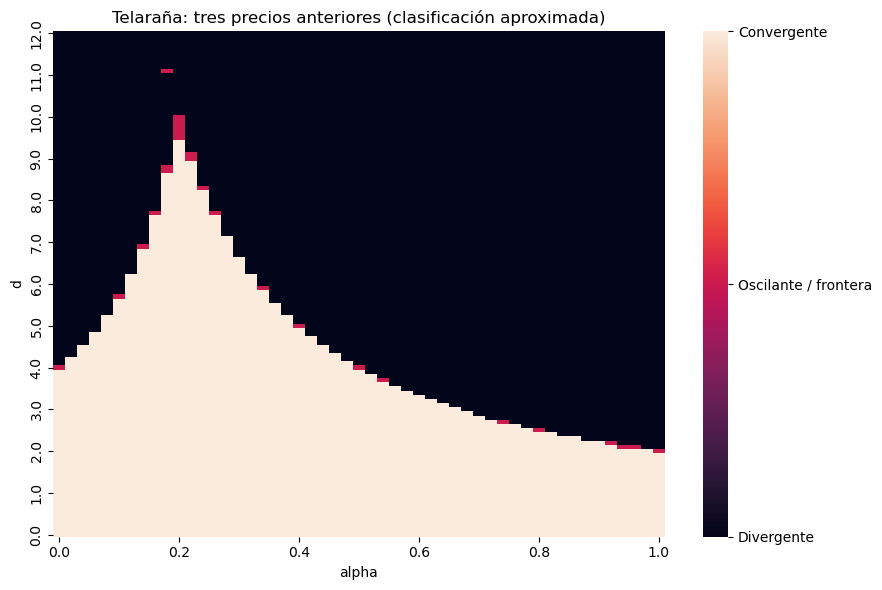

In [17]:
# Definición del modelo con tres precios anteriores
def ge_c(p, t, a, b, c, d, alpha):
    pes = ((1-alpha)/2)*(p[0] + p[1]) + alpha*p[2]
    ps = (a - supply(pes, c, d))/b
    return np.array([ps, p[0], p[1]])

# Definición de las condiciones iniciales y el intervalo de tiempo
a = 14
b = 2
c = 2
p2 = 2
p1 = 1
p0 = 1
p_c = [p2, p1, p0]
t_heat_c = np.arange(2, 1003)

# Barrido de alpha y d
d_array_heat = np.round(np.linspace(0, 12, 121), 2)
alpha_array_heat = np.round(np.linspace(0, 1, 51), 2)

def sweep_alpha_c(alpha_array, d):
    sweep = pd.Series(index=alpha_array, dtype=float)
    p_equilibrio = (a-c)/(b+d)
    for alpha in alpha_array:
        with np.errstate(over="ignore", invalid="ignore"):
            sol = solve_disc_model(ge_c, p_c, t_heat_c, arg=(a, b, c, d, alpha))
        sweep.loc[alpha] = clasificar_trayectoria(sol[:, 0], p_equilibrio)
    return sweep

def sweep_parameters_c(alpha_array, d_array):
    frame = pd.DataFrame(index=d_array, columns=alpha_array, dtype=float)
    for d in d_array:
        frame.loc[d] = sweep_alpha_c(alpha_array, d)
    return frame

frame_c = sweep_parameters_c(alpha_array_heat, d_array_heat)

# Gráfica del mapa de calor
plt.figure(figsize=(9, 6))
hm = sns.heatmap(frame_c, annot=False, vmin=0, vmax=1,
                 xticklabels=10, yticklabels=10,
                 cbar_kws={"ticks": [0, 0.5, 1]})
hm.invert_yaxis()
barra = hm.collections[0].colorbar
barra.set_ticklabels(["Divergente", "Oscilante / frontera", "Convergente"])
plt.xlabel("alpha")
plt.ylabel("d")
plt.title("Telaraña: tres precios anteriores (clasificación aproximada)")
plt.tight_layout()
plt.show()

**Interpretación.** El equilibrio continúa siendo $p^*=12/(2+d)$. Al comparar
(b) y (c), los ejes, los rangos y el criterio son los mismos: las diferencias
del mapa proceden del historial utilizado. Con $\alpha=0.5$ la frontera vuelve
a situarse cerca de $d=4$; añadir un precio no implica necesariamente aumentar
el umbral. Cerca de las fronteras se debe ampliar el horizonte o afinar los
parámetros antes de asegurar un comportamiento asintótico.


**(d)** Analizar el efecto del incremento de periodos que se toman para estimar precios $N$ sobre los valores umbrales de convergencia para el parámetros $d$. O sea, fijado $\alpha=0.5$ la ponderación el precio más alejado y el resto de las ponderaciones iguales, realizar una gráfica que relacione $N$ con el parámetro $d$ y que indique umbrales de convergencia.

Estudiamos cómo cambia el umbral de convergencia al utilizar **$N$ precios anteriores**, manteniendo $\alpha=0.5$. Para $N\geq2$, el precio más antiguo recibe peso $0.5$ y los otros $N-1$ se reparten el resto: cada uno recibe peso $0.5/(N-1)$.

Guardamos los precios del más reciente al más antiguo. La expectativa es la mitad de la media de los $N-1$ más recientes más la mitad del más antiguo. Calculamos el nuevo precio y desplazamos el historial. El equilibrio sigue siendo **$p^*=12/(2+d)$**.

Probamos **$N=1,2,\ldots,20$**. Para $N=1$ recuperamos el caso clásico: la expectativa depende del único precio disponible. El precio más reciente empieza en $2$ y los demás en $1$: para $N=2$ el estado es $[2,1]$ y para $N=3$ es $[2,1,1]$, como en b y c.

Usamos el mismo criterio de amplitudes, con un margen del $5\%$. Al aumentar $N$, la forma de las oscilaciones puede variar durante intervalos largos; por eso simulamos $1200N$ instantes y comparamos las dos ventanas finales de $500N$ años. Las ventanas más amplias ayudan a distinguir una amortiguación de las variaciones de amplitud entre ciclos.

In [18]:
# Valores de los parámetros
a = 14
b = 2
c = 2
alpha = 0.5
N_array = np.arange(1, 21)

# Modelo con N precios: del más reciente al más antiguo
def ge_N(p, t, a, b, c, d, alpha):
    if len(p) == 1:
        pes = p[0]  # Referencia: modelo clásico
    else:
        pes = (1-alpha)*np.mean(p[:-1])+alpha*p[-1]
    ps = a/b-supply(pes, c, d)/b
    return np.concatenate(([ps], p[:-1]))

# Clasificación: 0 divergente, 0.5 sin cambio claro, 1 convergente
def clasificar_d(N, d):
    p_inicial = np.ones(N)
    p_inicial[0] = 2.0
    t_d = np.arange(N-1, N-1+1200*N)
    ventana_d = 500*N
    margen_d = 0.05
    tolerancia_d = 1e-6

    with np.errstate(over='ignore', invalid='ignore'):
        sol = solve_disc_model(ge_N, p_inicial, t_d,
                               arg=(a, b, c, d, alpha))
    precios = sol[:, 0]
    if not np.all(np.isfinite(precios)):
        return 0.0

    p_equilibrio = (a-c)/(b+d)
    distancias = np.abs(precios-p_equilibrio)
    amplitud_anterior = np.max(distancias[-2*ventana_d:-ventana_d])
    amplitud_final = np.max(distancias[-ventana_d:])
    tolerancia_precio = tolerancia_d*max(1, abs(p_equilibrio))

    if amplitud_final < tolerancia_precio:
        return 1.0
    elif amplitud_final < (1-margen_d)*amplitud_anterior:
        return 1.0
    elif amplitud_final > (1+margen_d)*amplitud_anterior:
        return 0.0
    else:
        return 0.5

Para cada $N$ hacemos un barrido de $d$ entre $0.1$ y $6$, con paso $0.1$. Buscamos el **primer cambio de convergencia a divergencia**: tomamos el primer valor clasificado como divergente y el último convergente anterior a él. El punto medio sirve como estimación del umbral.

No utilizamos valores convergentes que puedan aparecer después de ese primer cambio. Esto evita que el caso especial $N=1$, $d=4$, cuya trayectoria empieza exactamente en el equilibrio, altere la estimación del umbral clásico.

La banda de la gráfica muestra la separación entre el último valor convergente y el primero divergente del barrido. Es una estimación numérica que depende del paso de $d$, de la duración de las simulaciones y del criterio de amplitudes.

In [19]:
# Barrido de d para cada número de precios anteriores
d_array_d = np.linspace(0.1, 6.0, 60)
resumen_d = []
resultados_d = {}

print(' N   Último convergente   Primero divergente   Umbral estimado')
for N in N_array:
    resultados = np.array([clasificar_d(N, d) for d in d_array_d])
    resultados_d[N] = resultados

    divergentes = d_array_d[resultados == 0]
    if len(divergentes) == 0:
        raise RuntimeError('Es necesario ampliar el rango de d.')
    d_superior = divergentes[0]

    convergentes = d_array_d[(resultados == 1) & (d_array_d < d_superior)]
    if len(convergentes) == 0:
        raise RuntimeError('No se ha encontrado un valor convergente previo.')
    d_inferior = convergentes[-1]
    d_estimado = (d_inferior+d_superior)/2

    resumen_d.append([N, d_inferior, d_superior, d_estimado])
    print(f'{N:2d}   {d_inferior:18.2f}   {d_superior:18.2f}   {d_estimado:15.2f}', flush=True)

tabla_umbrales = pd.DataFrame(resumen_d, columns=[
    'N', 'Último convergente', 'Primero divergente', 'Umbral estimado'
])

 N   Último convergente   Primero divergente   Umbral estimado
 1                 1.90                 2.10              2.00
 2                 3.90                 4.10              4.00
 3                 3.90                 4.10              4.00
 4                 3.90                 4.10              4.00
 5                 3.90                 4.10              4.00
 6                 3.90                 4.10              4.00
 7                 3.90                 4.10              4.00
 8                 3.90                 4.10              4.00
 9                 3.90                 4.10              4.00
10                 3.90                 4.10              4.00
11                 3.90                 4.10              4.00
12                 3.90                 4.10              4.00
13                 3.90                 4.10              4.00
14                 3.90                 4.10              4.00
15                 3.90                 4.10           

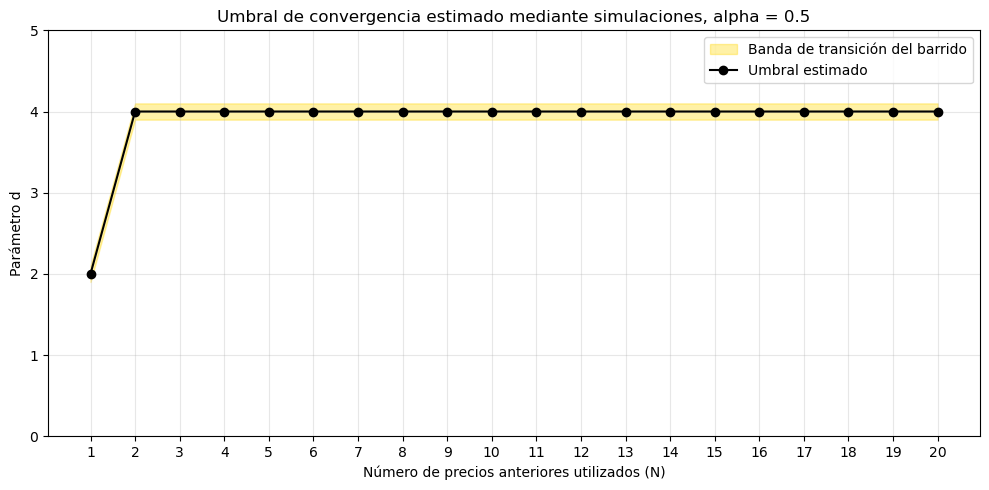

In [20]:
# Gráfica de los umbrales estimados
plt.figure(figsize=(10, 5))
plt.fill_between(
    tabla_umbrales['N'],
    tabla_umbrales['Último convergente'],
    tabla_umbrales['Primero divergente'],
    color='gold', alpha=0.35, label='Banda de transición del barrido'
)
plt.plot(tabla_umbrales['N'], tabla_umbrales['Umbral estimado'],
         'ko-', label='Umbral estimado')
plt.xticks(N_array)
plt.ylim(0, 5)
plt.xlabel('Número de precios anteriores utilizados (N)')
plt.ylabel('Parámetro d')
plt.title('Umbral de convergencia estimado mediante simulaciones, alpha = 0.5')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Resultado.** Para **$N=1$**, las simulaciones sitúan el umbral alrededor de **$d=2$**, como en a. Al pasar a **$N=2$**, aumenta aproximadamente a **$d=4$**. En los valores estudiados, de **$N=2$ a $N=20$**, se mantiene alrededor de $4$, dentro de la precisión del barrido.

Con este reparto de pesos y $\alpha=0.5$, añadir más precios después de los dos primeros **no produce un aumento continuado del umbral observado**. Puede cambiar la forma y la velocidad de las oscilaciones, pero no se aprecia una ampliación adicional clara de la región convergente. Los umbrales y la banda mostrada son aproximaciones obtenidas mediante simulaciones.